In [1]:
# Setup

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('../../../results/figures/eda_processed', exist_ok=True)

df = pd.read_csv('../../../data/processed/df_final.csv')

# ============================================================
# Dataset Validation
# ============================================================

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

required_engineered_features = [
    'goals_per_90',
    'assists_per_90',
    'goal_contribution_per_90',
    'minutes_per_game'
]

missing_features = [
    col for col in required_engineered_features
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing engineered features: {missing_features}"
    )

print("\nEngineered features successfully loaded.")

Dataset shape: (28028, 24)

Columns:
['player_id', 'player_name', 'total_goals', 'total_assists', 'total_yellow', 'total_red', 'total_minutes', 'total_games', 'goal_contribution', 'position', 'sub_position', 'country_of_citizenship', 'height_in_cm', 'market_value_in_eur', 'highest_market_value_in_eur', 'international_caps', 'international_goals', 'age', 'position_encoded', 'sub_position_encoded', 'goals_per_90', 'assists_per_90', 'goal_contribution_per_90', 'minutes_per_game']

Engineered features successfully loaded.


In [2]:
# Basic Statistics Overview

print("=== Dataset Overview ===")
print(f"Total players     : {len(df):,}")
print(f"Total positions   : {df['position'].nunique()}")
print(f"Total countries   : {df['country_of_citizenship'].nunique()}")
print(f"\nMarket Value:")
print(f"  Min    : €{df['market_value_in_eur'].min():>15,.0f}")
print(f"  Median : €{df['market_value_in_eur'].median():>15,.0f}")
print(f"  Mean   : €{df['market_value_in_eur'].mean():>15,.0f}")
print(f"  Max    : €{df['market_value_in_eur'].max():>15,.0f}")
print(f"  Skew   : {df['market_value_in_eur'].skew():.2f}")

print(f"\nAge range: {df['age'].min():.0f} → {df['age'].max():.0f} years")
print(f"\nNumerical Summary:")
print(df.describe().round(2))

=== Dataset Overview ===
Total players     : 28,028
Total positions   : 5
Total countries   : 181

Market Value:
  Min    : €         10,000
  Median : €        300,000
  Mean   : €      1,987,149
  Max    : €    200,000,000
  Skew   : 9.94

Age range: 14 → 54 years

Numerical Summary:
        player_id  total_goals  total_assists  total_yellow  total_red  \
count    28028.00     28028.00       28028.00      28028.00   28028.00   
mean    344359.56         6.41           5.04          9.75       0.23   
std     298943.53        17.16          11.40         15.03       0.61   
min         10.00         0.00           0.00          0.00       0.00   
25%      91431.75         0.00           0.00          1.00       0.00   
50%     265487.50         1.00           1.00          4.00       0.00   
75%     525022.25         5.00           5.00         13.00       0.00   
max    1510255.00       527.00         224.00        147.00       8.00   

       total_minutes  total_games  goal_contri

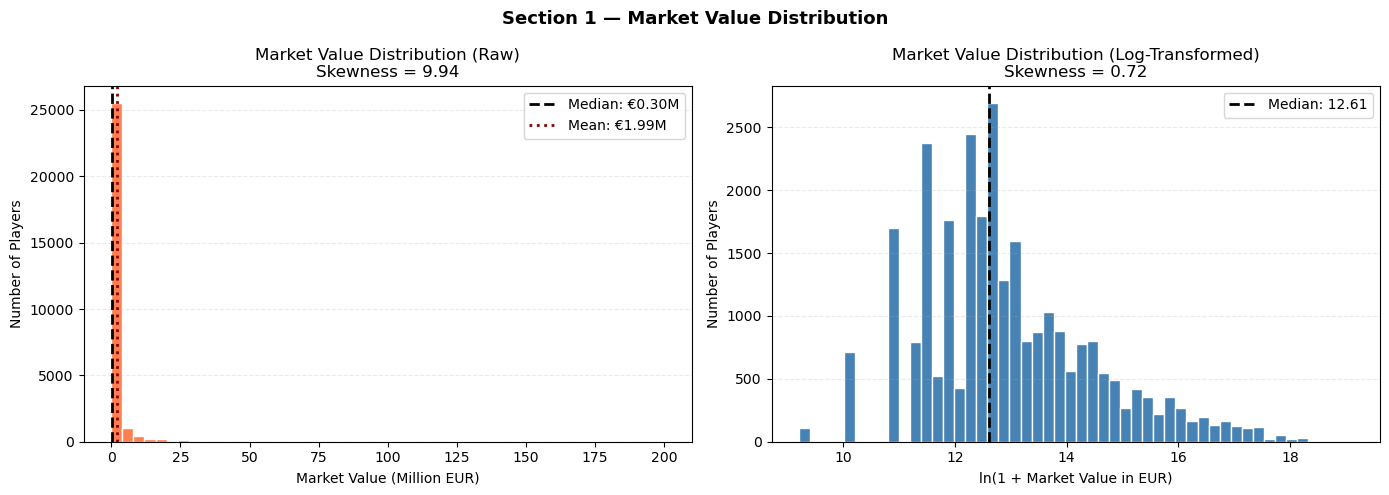

Saved


In [3]:
# Market Value Distribution
 
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) 
 
# Raw distribution 
axes[0].hist(df['market_value_in_eur'] / 1_000_000, 
bins=50, color='coral', edgecolor='white') 

axes[0].set_title(f'Market Value Distribution (Raw)\n' 
f'Skewness = {df["market_value_in_eur"].skew():.2f}') 

axes[0].set_xlabel('Market Value (Million EUR)') 
axes[0].set_ylabel('Number of Players') 

# Median line
axes[0].axvline(df['market_value_in_eur'].median() / 1_000_000, 
color='black', linestyle='--', linewidth=2, 
label=f'Median: €{df["market_value_in_eur"].median()/1e6:.2f}M') 

# Mean line
axes[0].axvline(df['market_value_in_eur'].mean() / 1_000_000,
color='darkred', linestyle=':', linewidth=2,
label=f'Mean: €{df["market_value_in_eur"].mean()/1e6:.2f}M')

axes[0].legend() 
axes[0].grid(axis='y', linestyle='--', alpha=0.25)
 
# Log-transformed distribution 
log_mv = np.log1p(df['market_value_in_eur']) 

axes[1].hist(log_mv, bins=50, 
color='steelblue', edgecolor='white') 

axes[1].set_title(f'Market Value Distribution (Log-Transformed)\n' 
f'Skewness = {log_mv.skew():.2f}') 

axes[1].set_xlabel('ln(1 + Market Value in EUR)') 
axes[1].set_ylabel('Number of Players') 

axes[1].axvline(log_mv.median(), color='black', 
linestyle='--', linewidth=2, 
label=f'Median: {log_mv.median():.2f}') 

axes[1].legend() 
axes[1].grid(axis='y', linestyle='--', alpha=0.25)
 
plt.suptitle('Section 1 — Market Value Distribution', 
fontsize=13, fontweight='bold') 

plt.tight_layout() 

plt.savefig('../../../results/figures/eda_processed/S1_market_value_dist.png',
dpi=150, bbox_inches='tight') 

plt.show() 

print("Saved")

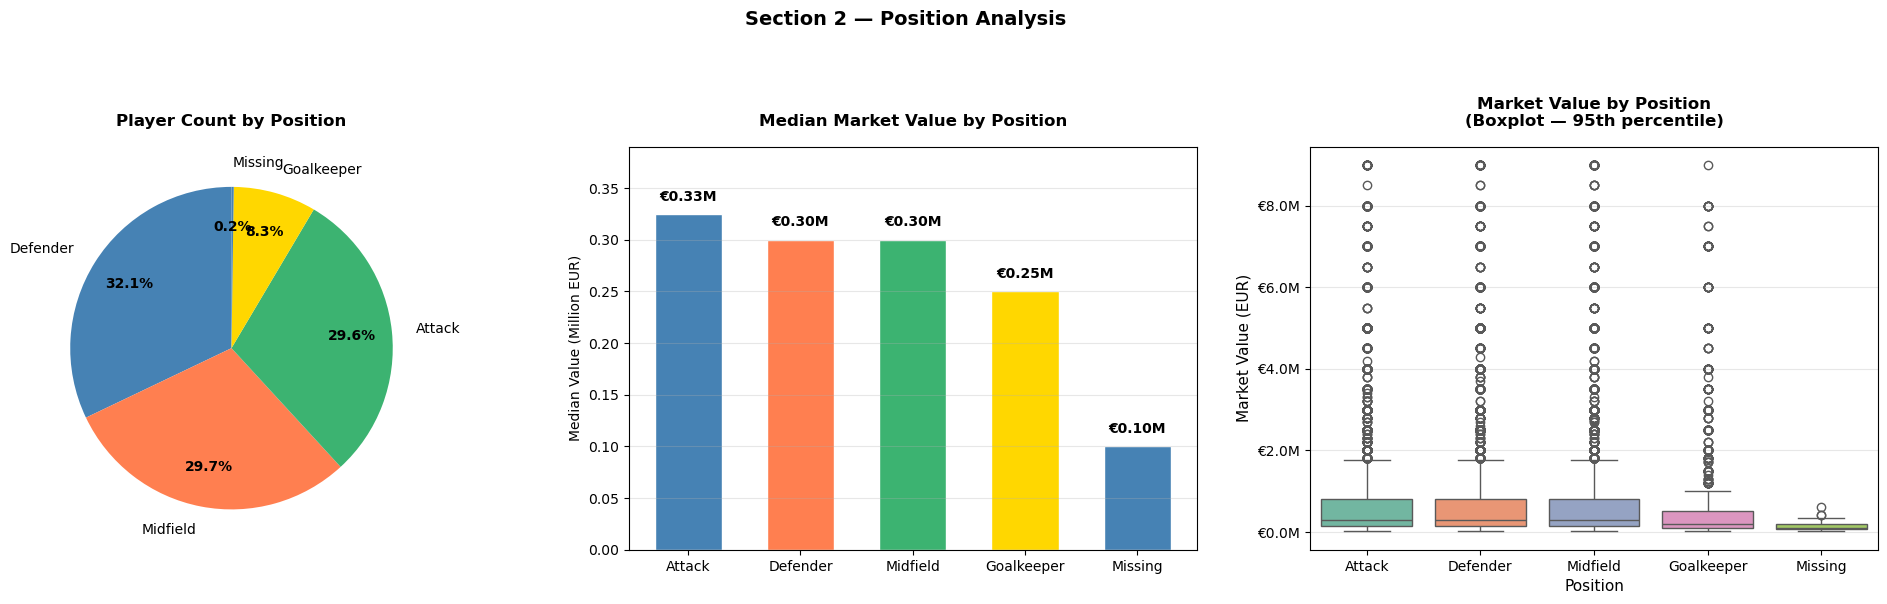

Saved


In [4]:
# Section 2: Position Analysis

fig = plt.figure(figsize=(20, 6))

# == Chart 1 — Pie chart ==
ax1 = fig.add_subplot(1, 3, 1)
pos_counts = df['position'].value_counts()
wedges, texts, autotexts = ax1.pie(
    pos_counts.values,
    labels=pos_counts.index,
    autopct='%1.1f%%',
    colors=['steelblue', 'coral', 'mediumseagreen', 'gold'],
    startangle=90,
    pctdistance=0.75,    
    labeldistance=1.15   
)
for text in autotexts:
    text.set_fontsize(10)
    text.set_fontweight('bold')
ax1.set_title('Player Count by Position',
              fontsize=12, fontweight='bold', pad=15)

# == Chart 2 — Bar chart ==
ax2 = fig.add_subplot(1, 3, 2)
pos_med = df.groupby('position')['market_value_in_eur']\
            .median().sort_values(ascending=False)
bars = ax2.bar(pos_med.index,
               pos_med.values / 1_000_000,
               color=['steelblue', 'coral', 'mediumseagreen', 'gold'],
               edgecolor='white', width=0.6)
ax2.set_title('Median Market Value by Position',
              fontsize=12, fontweight='bold', pad=15)
ax2.set_ylabel('Median Value (Million EUR)')
ax2.set_ylim(0, pos_med.max() / 1_000_000 * 1.2)  
for bar, v in zip(bars, pos_med.values / 1_000_000):
    ax2.text(bar.get_x() + bar.get_width() / 2,
             v + 0.01,
             f'€{v:.2f}M',
             ha='center', va='bottom',
             fontsize=10, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

# == Chart 3 — Boxplot ==
ax3 = fig.add_subplot(1, 3, 3)
df_box = df[df['market_value_in_eur'] <=
            df['market_value_in_eur'].quantile(0.95)].copy()
pos_order = df_box.groupby('position')['market_value_in_eur']\
                  .median().sort_values(ascending=False).index.tolist()

sns.boxplot(data=df_box,
            x='position', y='market_value_in_eur',
            hue='position', order=pos_order,
            hue_order=pos_order,
            palette='Set2', legend=False, ax=ax3)

ax3.set_title('Market Value by Position\n(Boxplot — 95th percentile)',
              fontsize=12, fontweight='bold', pad=15)
ax3.set_xlabel('Position', fontsize=11)
ax3.set_ylabel('Market Value (EUR)', fontsize=11)
ax3.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'€{x/1e6:.1f}M')
)
ax3.grid(axis='y', alpha=0.3)

plt.suptitle('Section 2 — Position Analysis',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout(pad=2.0)
plt.savefig('../../../results/figures/eda_processed/S2_position_analysis.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

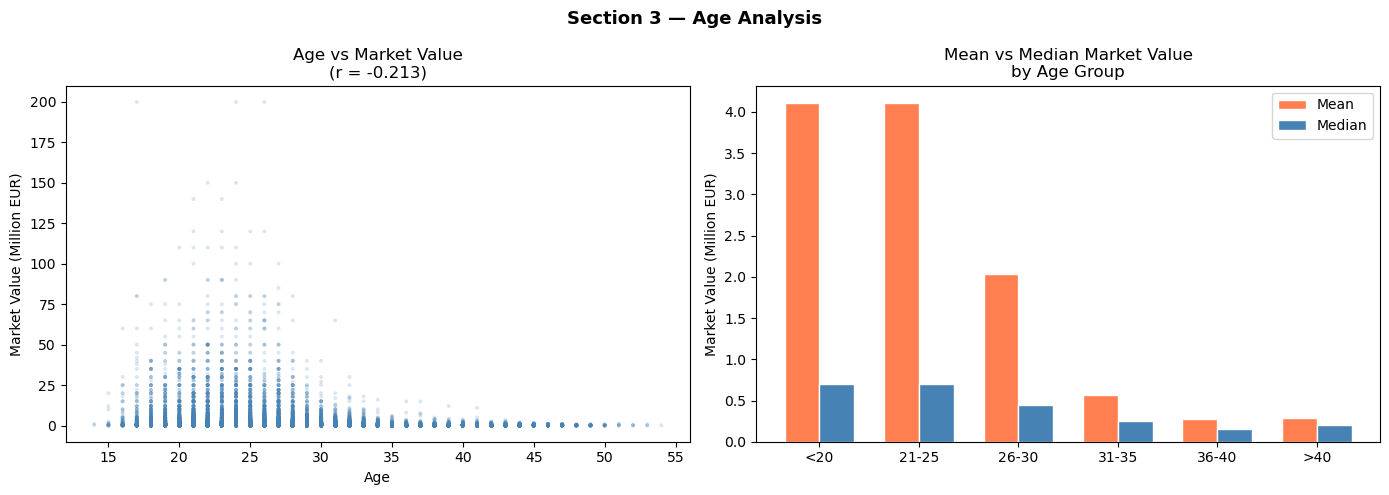

Saved


In [5]:
# Section 3: Age Analysis

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter age vs value
axes[0].scatter(df['age'],
                df['market_value_in_eur'] / 1_000_000,
                alpha=0.2, color='steelblue', edgecolors='none', s=8)
r = df['age'].corr(df['market_value_in_eur'])
axes[0].set_title(f'Age vs Market Value\n(r = {r:.3f})')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Market Value (Million EUR)')

# Mean vs Median by age group
df['age_group'] = pd.cut(df['age'],
                          bins=[14, 20, 25, 30, 35, 40, 55],
                          labels=['<20', '21-25', '26-30',
                                  '31-35', '36-40', '>40'])
age_stats = df.groupby('age_group', observed=True)['market_value_in_eur']\
              .agg(['mean', 'median']).reset_index()

x     = range(len(age_stats))
width = 0.35
axes[1].bar([i - width/2 for i in x],
            age_stats['mean'] / 1_000_000,
            width, label='Mean', color='coral', edgecolor='white')
axes[1].bar([i + width/2 for i in x],
            age_stats['median'] / 1_000_000,
            width, label='Median', color='steelblue', edgecolor='white')
axes[1].set_title('Mean vs Median Market Value\nby Age Group')
axes[1].set_ylabel('Market Value (Million EUR)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(age_stats['age_group'])
axes[1].legend()

plt.suptitle('Section 3 — Age Analysis',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/eda_processed/S3_age_analysis.png', dpi=150)
plt.show()
print("Saved")

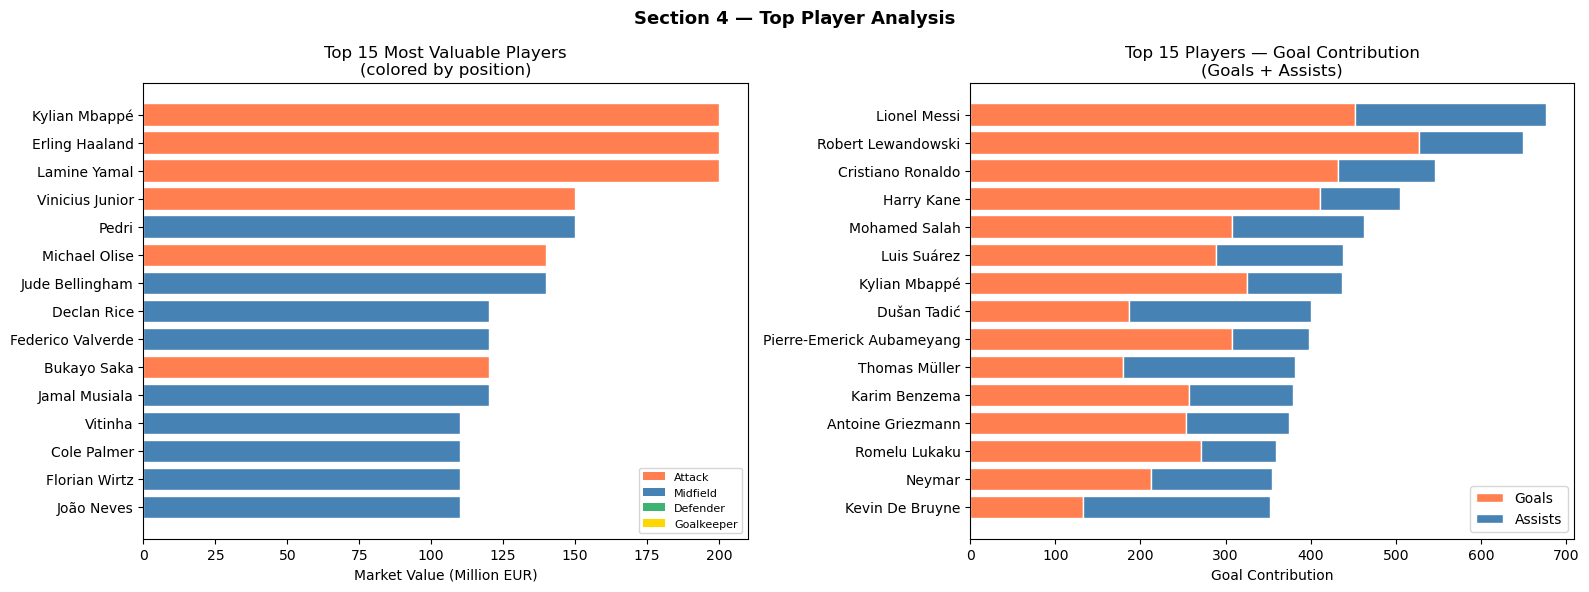

Saved


In [6]:
# Section 4: Top Players

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 15 most valuable
top15 = df.nlargest(15, 'market_value_in_eur')[
    ['player_name', 'market_value_in_eur', 'position']
]
colors_pos = {'Attack': 'coral', 'Midfield': 'steelblue',
              'Defender': 'mediumseagreen', 'Goalkeeper': 'gold'}
bar_colors = [colors_pos.get(p, 'gray') for p in top15['position']]

axes[0].barh(top15['player_name'],
             top15['market_value_in_eur'] / 1_000_000,
             color=bar_colors, edgecolor='white')
axes[0].set_title('Top 15 Most Valuable Players\n(colored by position)')
axes[0].set_xlabel('Market Value (Million EUR)')
axes[0].invert_yaxis()

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=v, label=k)
                   for k, v in colors_pos.items()]
axes[0].legend(handles=legend_elements, loc='lower right', fontsize=8)

# Top 15 by goal contribution
top15_gc = df.nlargest(15, 'goal_contribution')[
    ['player_name', 'total_goals', 'total_assists', 'goal_contribution']
]
axes[1].barh(top15_gc['player_name'], top15_gc['total_goals'],
             color='coral', edgecolor='white', label='Goals')
axes[1].barh(top15_gc['player_name'], top15_gc['total_assists'],
             left=top15_gc['total_goals'],
             color='steelblue', edgecolor='white', label='Assists')
axes[1].set_title('Top 15 Players — Goal Contribution\n(Goals + Assists)')
axes[1].set_xlabel('Goal Contribution')
axes[1].invert_yaxis()
axes[1].legend()

plt.suptitle('Section 4 — Top Player Analysis',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/eda_processed/S4_top_players.png', dpi=150)
plt.show()
print("Saved")

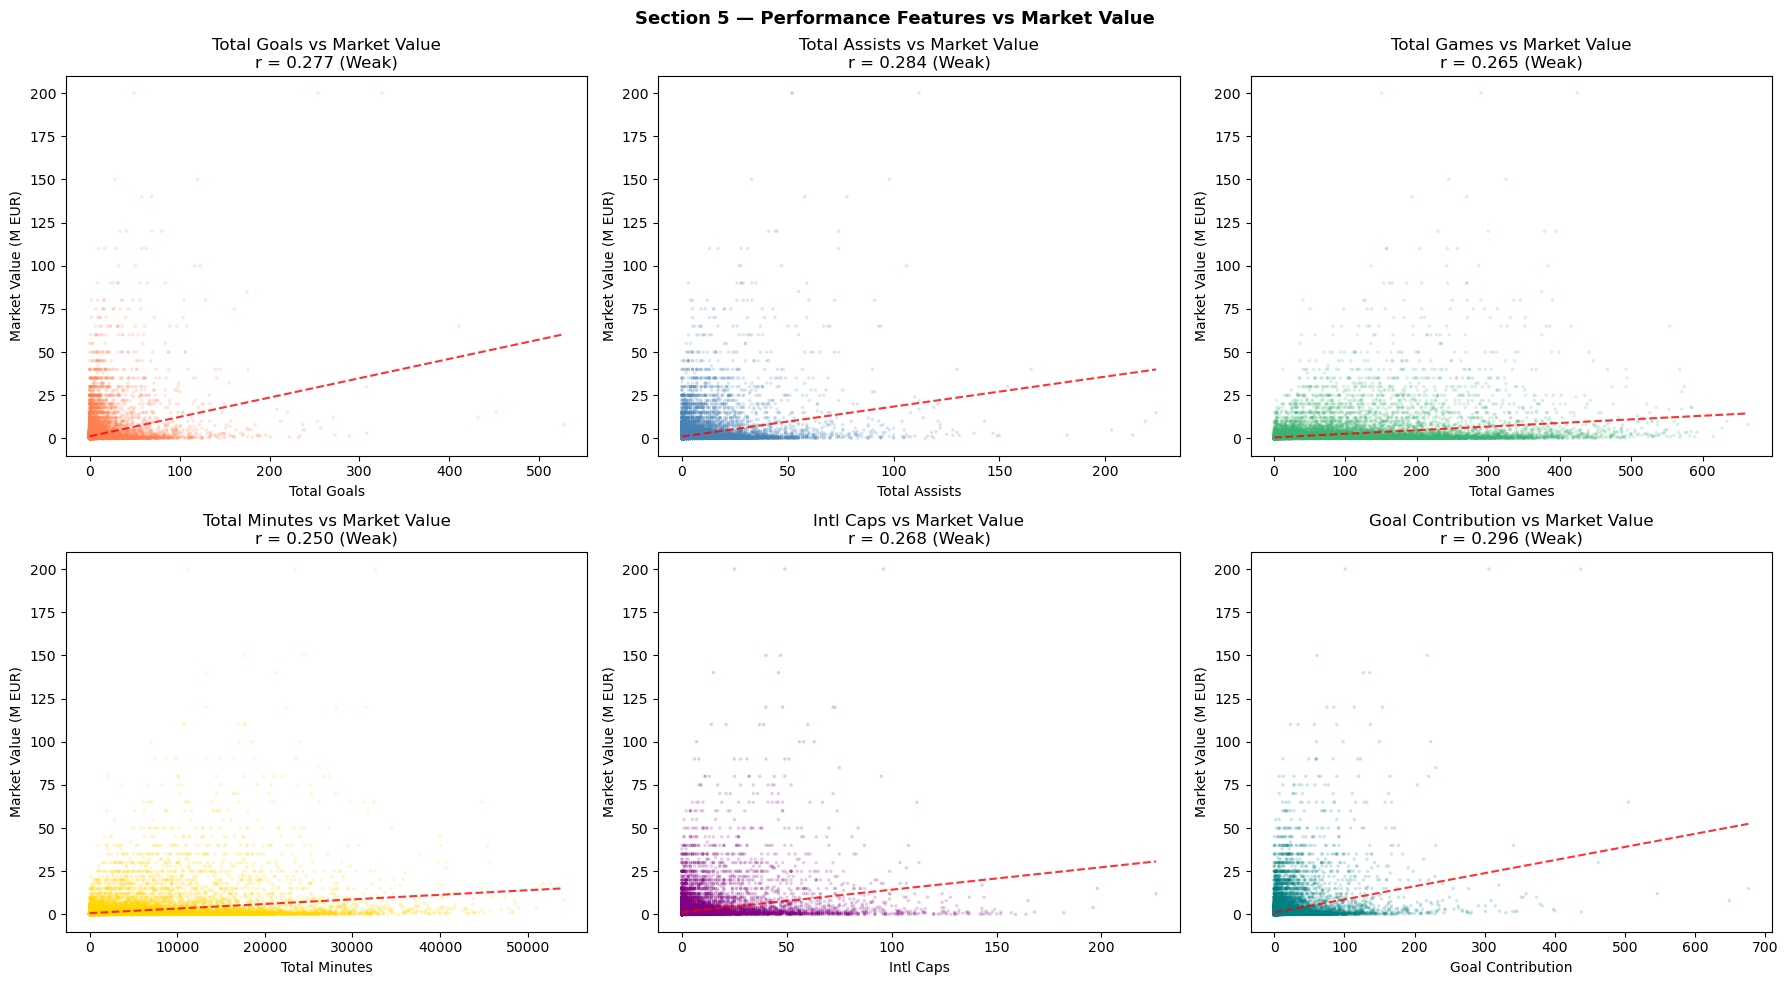

Saved


In [7]:
# Section 5: Performance and Market Value

features = [
    ('total_goals',       'Total Goals',       'coral'),
    ('total_assists',     'Total Assists',      'steelblue'),
    ('total_games',       'Total Games',        'mediumseagreen'),
    ('total_minutes',     'Total Minutes',      'gold'),
    ('international_caps','Intl Caps',          'purple'),
    ('goal_contribution', 'Goal Contribution',  'teal'),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (col, label, color) in zip(axes.flatten(), features):
    data = df.dropna(subset=[col])
    r    = data[col].corr(data['market_value_in_eur'])

    ax.scatter(data[col],
               data['market_value_in_eur'] / 1_000_000,
               alpha=0.2, color=color, edgecolors='none', s=6)

    # Trend line
    z      = np.polyfit(data[col],
                        data['market_value_in_eur'] / 1_000_000, 1)
    p      = np.poly1d(z)
    x_line = np.linspace(data[col].min(), data[col].max(), 100)
    ax.plot(x_line, p(x_line), 'r--', linewidth=1.5, alpha=0.8)

    strength = ('Strong'   if abs(r) > 0.5 else
                'Moderate' if abs(r) > 0.3 else 'Weak')
    ax.set_title(f'{label} vs Market Value\nr = {r:.3f} ({strength})')
    ax.set_xlabel(label)
    ax.set_ylabel('Market Value (M EUR)')

plt.suptitle('Section 5 — Performance Features vs Market Value',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/eda_processed/S5_performance_vs_value.png', dpi=150)
plt.show()
print("Saved")

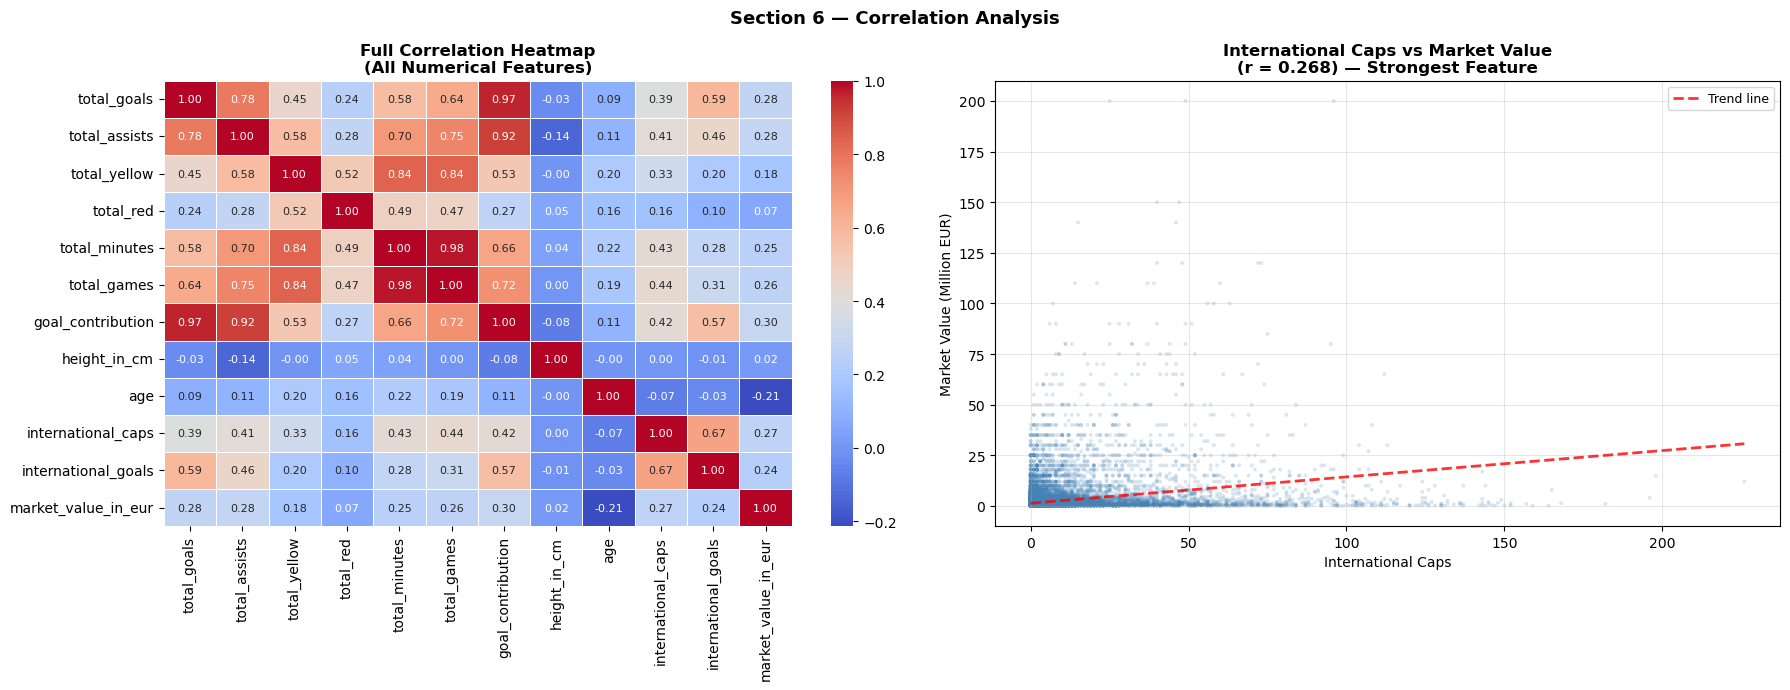

Saved


In [8]:
# Section 6: Correlation Analysis
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

numerical_cols = ['total_goals', 'total_assists', 'total_yellow',
                  'total_red', 'total_minutes', 'total_games',
                  'goal_contribution', 'height_in_cm', 'age',
                  'international_caps', 'international_goals',
                  'market_value_in_eur']

# Chart 1 — Full Heatmap (giữ nguyên)
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f',
            cmap='coolwarm', linewidths=0.5,
            ax=axes[0], annot_kws={'size': 8})
axes[0].set_title('Full Correlation Heatmap\n(All Numerical Features)',
                  fontsize=12, fontweight='bold')

# Chart 2 — Scatter: international_caps vs market_value
# (feature có r cao nhất với target)
data = df.dropna(subset=['international_caps'])
r    = data['international_caps'].corr(data['market_value_in_eur'])

axes[1].scatter(data['international_caps'],
                data['market_value_in_eur'] / 1_000_000,
                alpha=0.2, color='steelblue', edgecolors='none', s=8)

# Trend line
z      = np.polyfit(data['international_caps'],
                    data['market_value_in_eur'] / 1_000_000, 1)
p      = np.poly1d(z)
x_line = np.linspace(data['international_caps'].min(),
                     data['international_caps'].max(), 100)
axes[1].plot(x_line, p(x_line), 'r--', linewidth=2, alpha=0.8,
             label='Trend line')

axes[1].set_title(f'International Caps vs Market Value\n'
                  f'(r = {r:.3f}) — Strongest Feature',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('International Caps')
axes[1].set_ylabel('Market Value (Million EUR)')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.suptitle('Section 6 — Correlation Analysis',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/eda_processed/S6_correlation_heatmap.png', dpi=150)
plt.show()
print("Saved")

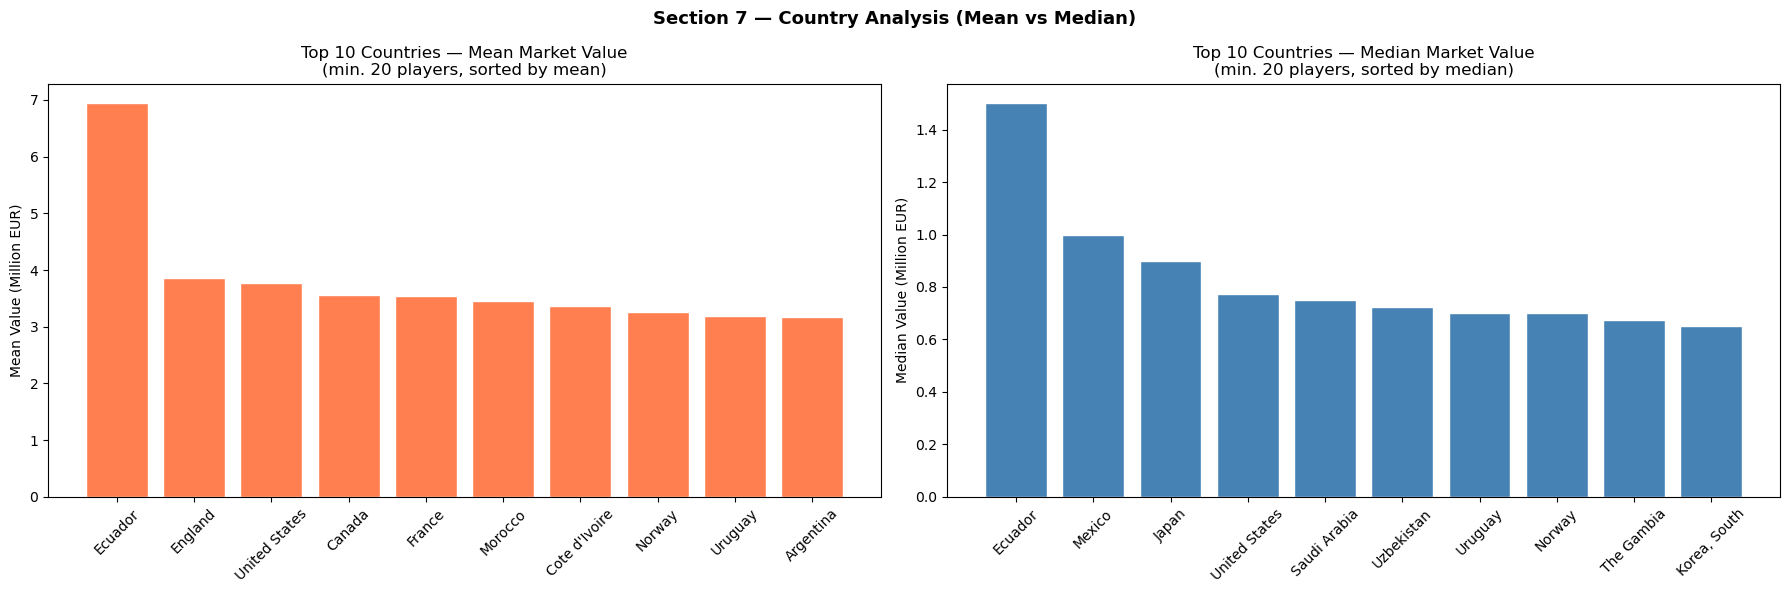

Saved


In [9]:
# Section 7: Country Analysis

country_stats = df.groupby('country_of_citizenship').agg(
    avg_value   = ('market_value_in_eur', 'mean'),
    med_value   = ('market_value_in_eur', 'median'),
    num_players = ('player_id',           'count')
).reset_index()

filtered = country_stats[country_stats['num_players'] >= 20]
top_mean   = filtered.sort_values('avg_value',  ascending=False).head(10)
top_median = filtered.sort_values('med_value', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].bar(top_mean['country_of_citizenship'],
            top_mean['avg_value'] / 1_000_000,
            color='coral', edgecolor='white')
axes[0].set_title('Top 10 Countries — Mean Market Value\n(min. 20 players, sorted by mean)')
axes[0].set_ylabel('Mean Value (Million EUR)')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(top_median['country_of_citizenship'],
            top_median['med_value'] / 1_000_000,
            color='steelblue', edgecolor='white')
axes[1].set_title('Top 10 Countries — Median Market Value\n(min. 20 players, sorted by median)')
axes[1].set_ylabel('Median Value (Million EUR)')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Section 7 — Country Analysis (Mean vs Median)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/eda_processed/S7_country_analysis.png', dpi=150)
plt.show()
print("Saved")

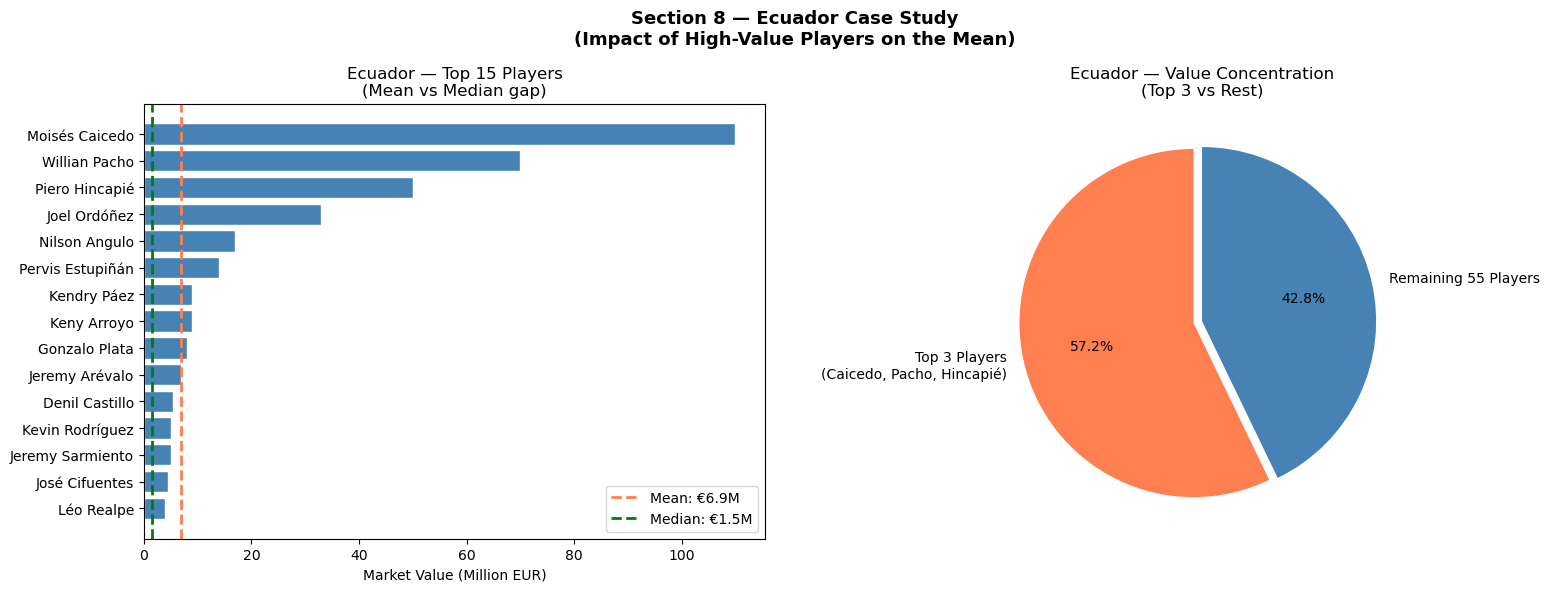

Saved


In [10]:
# Section 8: Outlier Case Study

ecuador = df[df['country_of_citizenship'] == 'Ecuador'].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart top 15
ec_top = ecuador.sort_values('market_value_in_eur', ascending=False).head(15)
axes[0].barh(ec_top['player_name'],
             ec_top['market_value_in_eur'] / 1_000_000,
             color='steelblue', edgecolor='white')
axes[0].axvline(ecuador['market_value_in_eur'].mean() / 1_000_000,
                color='coral', linestyle='--', linewidth=2,
                label=f"Mean: €{ecuador['market_value_in_eur'].mean()/1e6:.1f}M")
axes[0].axvline(ecuador['market_value_in_eur'].median() / 1_000_000,
                color='green', linestyle='--', linewidth=2,
                label=f"Median: €{ecuador['market_value_in_eur'].median()/1e6:.1f}M")
axes[0].set_title('Ecuador — Top 15 Players\n(Mean vs Median gap)')
axes[0].set_xlabel('Market Value (Million EUR)')
axes[0].invert_yaxis()
axes[0].legend()

# Pie chart
top3  = ecuador.nlargest(3, 'market_value_in_eur')['market_value_in_eur'].sum()
rest  = ecuador['market_value_in_eur'].sum() - top3
axes[1].pie([top3, rest],
            labels=['Top 3 Players\n(Caicedo, Pacho, Hincapié)',
                    f'Remaining {len(ecuador)-3} Players'],
            autopct='%1.1f%%',
            colors=['coral', 'steelblue'],
            startangle=90, explode=[0.05, 0])
axes[1].set_title('Ecuador — Value Concentration\n(Top 3 vs Rest)')

plt.suptitle('Section 8 — Ecuador Case Study\n'
             '(Impact of High-Value Players on the Mean)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/eda_processed/S8_ecuador_case_study.png', dpi=150)
plt.show()
print("Saved")

In [11]:
# Key Insights Summary

print("=" * 60)
print("EDA SUMMARY — Processed Data (df_final.csv)")
print("=" * 60)
print(f"""
Dataset: {len(df):,} players | {df.shape[1]} features | 0 missing

SECTION 1 — Distribution:
  Skewness raw   : {df['market_value_in_eur'].skew():.2f} → heavily right-skewed
  Skewness log   : {np.log1p(df['market_value_in_eur']).skew():.2f} → near normal
  Most players   : €163K - €1.2M range (log 12-14)

SECTION 2 — Position:
  Highest value  : {df.groupby('position')['market_value_in_eur'].median().idxmax()}
  Lowest value   : {df.groupby('position')['market_value_in_eur'].median().idxmin()}

SECTION 3 — Age:
  Peak value age : 21-25 (median €{df[df['age_group']=='21-25']['market_value_in_eur'].median()/1e6:.2f}M)
  Sharpest drop  : After 30

SECTION 5 — Strongest features:
  Top r values vs market_value:
{df[['total_goals','total_assists','total_games',
     'international_caps','age','market_value_in_eur']]\
     .corr()['market_value_in_eur'].drop('market_value_in_eur')\
     .sort_values(ascending=False).round(3).to_string()}

SECTION 8 — Outlier Case Study:
  Ecuador mean   : €{df[df['country_of_citizenship']=='Ecuador']['market_value_in_eur'].mean()/1e6:.1f}M
  Ecuador median : €{df[df['country_of_citizenship']=='Ecuador']['market_value_in_eur'].median()/1e6:.1f}M
  Gap            : {df[df['country_of_citizenship']=='Ecuador']['market_value_in_eur'].mean() / df[df['country_of_citizenship']=='Ecuador']['market_value_in_eur'].median():.1f}x
  → Top 3 players dominate value
""")

EDA SUMMARY — Processed Data (df_final.csv)

Dataset: 28,028 players | 25 features | 0 missing

SECTION 1 — Distribution:
  Skewness raw   : 9.94 → heavily right-skewed
  Skewness log   : 0.72 → near normal
  Most players   : €163K - €1.2M range (log 12-14)

SECTION 2 — Position:
  Highest value  : Attack
  Lowest value   : Missing

SECTION 3 — Age:
  Peak value age : 21-25 (median €0.70M)
  Sharpest drop  : After 30

SECTION 5 — Strongest features:
  Top r values vs market_value:
total_assists         0.284
total_goals           0.277
international_caps    0.268
total_games           0.265
age                  -0.213

SECTION 8 — Outlier Case Study:
  Ecuador mean   : €6.9M
  Ecuador median : €1.5M
  Gap            : 4.6x
  → Top 3 players dominate value

